# Introduction: Charles the Little's Catapult Challenge

Meet Charles the Little, a valiant warrior with a bold ambition: to conquer a formidable castle using his trusty catapult. Charles is not only skilled in warfare but is also intrigued by the wonders of mathematics and science. 

As he embarks on his conquest, Charles faces a puzzling dilemma. While he understands the mathematical model that describes the trajectory of projectiles thrown by the catapult, he realizes that this alone is not sufficient to accurately predict where the stones will land.   

Tasked with aiding Charles in his quest, you, the student, have the opportunity to apply your knowledge of state estimation and the Kalman Filter to enhance his catapult's accuracy. By incorporating measurements and utilizing the Kalman Filter, can you help Charles achieve his goal?
 
In this interactive workshop, you will explore how to implement the Kalman Filter to estimate the position and velocity of the thrown stones. Through a series of tasks and challenges, you'll enhance your understanding of state estimation and its real-world applications.

## Mathematical Model of Castle Attack

To strategize the attack on the castle, Charles the Little employs a mathematical model to understand the motion of the projectile launched from his catapult. The equations below provide insight into the trajectory of the projectile:

$$ \dot{s_x}(t) = v_{0} \cdot \cos(\theta_0)  $$
$$ \dot{s_y}(t) = v_{0} \cdot \sin(\theta_0) - g \cdot t $$

In this model, the following variables hold significance:
- $s_x$ and $s_y$ represent the position of the projectile in the horizontal and vertical directions, respectively.
- $v_0$ corresponds to the initial velocity imparted to the projectile.
- $\theta_0$ denotes the angle at which the catapult launches the projectile.
- $g$ symbolizes the acceleration due to gravity, a constant value.
- $t$ is the time variable that tracks the projectile's flight duration.

Through this mathematical framework, Charles aims to predict the trajectory of his projectiles and accurately target the castle walls. However, he soon discovers that external factors, like measurement errors, challenge the precision of his model. Charles realizes that incorporating observations and a filtering mechanism, such as the Kalman Filter, can enhance the accuracy of his attacks.

<div style="padding: 20px; border: 5px solid;">
    <h2>Interactive Code Block 1: Exploring the True Trajectory and Optimal Throwing Angle</h2>
    <p>Imagine stepping back in time to an era of castles and catapults, where Charles the Little is on a daring mission to conquer a formidable fortress. He's seeking your guidance to refine the accuracy of his trusty catapult.</p>  
    <p>Your first challenge is to unravel the mysteries of trajectory and determine the perfect angle for throwing a stone with Charles's catapult. By calculating and plotting the true trajectory of the thrown stone, you can assist Charles in his conquest.</p>   
    <h3>Tasks:</h3>
    <ol>
        <li>Implement the equations to calculate the true trajectory of the stone using the provided parameters.</li>
        <li>Utilize the provided utility functions to visualize the calculated true trajectory in the XY-plane. Set the time of landing as the last time step for accurate plotting.</li>
        <li>Discover the optimal angle of throwing that results in the stone covering the maximum distance.</li>
        <li>Calculate the precise time at which the stone lands and use this time for subsequent tasks.</li>
    </ol> 
    <p>Feel free to add new code cells below to complete the tasks.</p>
</div>

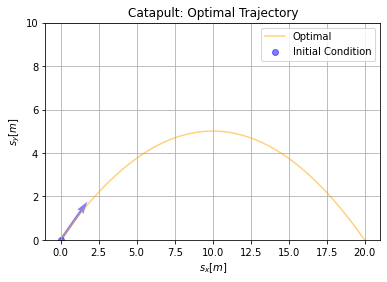

Optimal Throwing Angle: 45.08 degrees
Time of Landing: 2.02 seconds


In [1]:
# Import plotting and math library
import numpy as np
import utilities as ut

# Definitions of constants
speed = 14  # Speed of the throw [m/s]
theta = np.radians(50)  # Angle of throw [rad]
g = 9.81  # Gravity of earth [m/s^2]
p0 = np.array([[0],[0]]) # Position of ball at first time step [m]
t0 = 0 # Start time [s]

# Angle range for exploring optimal throwing angle
theta_range = np.linspace(0.1, np.pi / 2, 500)  # Divide 0.1 to pi/2 into 500 possible angles

# Initialize variables for finding optimal angle and time of landing
max_distance = 0
optimal_angle = 0
landing_time = 0

# Loop through different angles and find optimal angle
for angle in theta_range:
    v0 = np.array([[speed * np.cos(angle)], [speed * np.sin(angle)]]) # Compute the velocity components
    tf = 2.0 * (v0[1] / g)  # Conputer final time

    t_true = np.arange(t0, tf, 1e-5)  # Generate a dense time step vector for solution close to optimal
    s_true = np.array([
        np.multiply(v0[0], t_true),
        np.multiply(-0.5 * g, np.power(t_true, 2)) + np.multiply(v0[1], t_true)
    ])  # Generate xy coordinates of the true trajectory
    # Calculate the maximum distance for this angle
    distance = np.max(s_true[0, :])
    if distance > max_distance:
        max_distance = distance
        optimal_angle = angle
        landing_time = t_true[np.argmax(s_true[0, :])]

# Recomputre the values for the optimal angle for later use
v0 = np.array([[speed * np.cos(optimal_angle)], [speed * np.sin(optimal_angle)]])
tf = 2.0 * (v0[1] / g)

t_true = np.arange(0, tf, 1e-5)
s_true = np.array([
    np.multiply(v0[0], t_true),# - t_true,
    np.multiply(-0.5 * g, np.power(t_true, 2)) + np.multiply(v0[1], t_true)
])
    
# Use the utility function to plot the true trajectory of the ball
ut.plot_true_trajectory(p0, v0, s_true)  # Plot the start configuration and true trajectory

# Print the optimal angle and time of landing
print('Optimal Throwing Angle: {:.2f} degrees'.format(np.degrees(optimal_angle)))
print('Time of Landing: {:.2f} seconds'.format(landing_time))

<div style="padding: 20px; border: 5px solid;">
    <h2>Interactive Code Block 2: Observations and Error Analysis</h2>
    <p>Our journey alongside Charles the Little continues, and this time we find ourselves amidst a curious situation. Charles's trusty knights, responsible for tracking his stone's path through the air, seem to have found more entertainment in their goblets than their duties.</p>
    <p>Your mission in this task is to decipher the observations gathered by these jovial knights. Their haphazard measurements are a reflection of their jolly spirits, adding an extra layer of uncertainty to our estimation challenge.</p>  
    <h3>Tasks:</h3>
    <ol>
        <li>Create a list of observation times with a measurement rate of $10Hz$.</li>
        <li>Implement code to generate observations of the stone's position based on the true trajectory, taking into account the unpredictable measurements due to the inebriated knights.</li>
        <li>Visualize the actual trajectory, the unsteady observations, and the intriguing differences between them using the provided utility function.</li>
        <li>Uncover insights by calculating and presenting the average position error of the observations in comparison to the true trajectory.</li>
    </ol>
    <p>Feel free to add new code cells below to complete the tasks.</p>
</div>

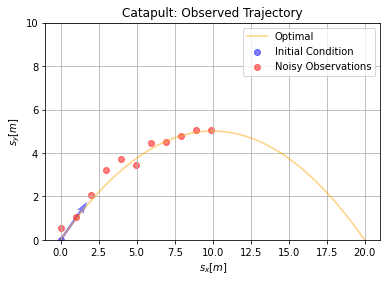

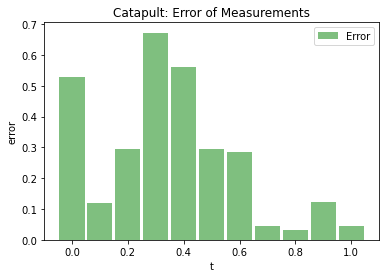

Mean Position Error of Observations: 0.2724 [m]


In [2]:
dt = 0.1  # Time step size
t_observed = np.arange(t0, 0.5*tf, dt)  # Generate time steps for observations

np.random.seed(0) # Ensure same errors each run

mu, sigma = 0, 0.3 # Mean and standard deviation of error
ey = np.random.normal(mu, sigma, len(t_observed)) # Create addative error vector
ex = np.zeros((len(t_observed))); #t_observed  # Create addative error vector
s_observed = np.array( [np.interp(t_observed, t_true, s_true[0,:]) - ex, np.interp(t_observed, t_true, s_true[1,:]) + ey]) # Add error to true value
    
ut.plot_true_and_observations(p0, v0, s_true, s_observed)  # Plot the start configuration, true trajectory, and observations

# Calculate the error between observations and true trajectory
s_true_sampled_observed = np.array([
    np.interp(t_observed, t_true, s_true[0, :]),
    np.interp(t_observed, t_true, s_true[1, :])
])
s_error_observed = np.linalg.norm(s_observed - s_true_sampled_observed, 2, 0)

ut.plot_error(t_observed, s_error_observed) # Plot the error

mean_error_observed = np.mean(s_error_observed) # Calculate mean error
print('Mean Position Error of Observations: {:.4f} [m]'.format(mean_error_observed))

<div style="padding: 20px; border: 5px solid;">
    <h2>Interactive Code Block 3: Kalman Filter Prediction and Update</h2>
    <p>As we continue our adventure with Charles the Little, a new chapter unfolds. Charles, a strategist at heart, realizes that predicting the path of his projectiles requires more than mere observation. With a touch of mathematical ingenuity, he introduces the Kalman Filter into the equation.</p>
    <p>Your role in this phase is to breathe life into Charles's innovative approach. Embrace the prediction and update steps of the Kalman Filter, and witness how its integration of system dynamics and measurement knowledge elevates our estimation accuracy beyond simple observations.</p>  
    <h3>Tasks:</h3>
    <ol>
        <li>Complete the provided code to implement the prediction part of the Kalman Filter.</li>
        <li>Visualize the error between predicted values and the true trajectory.</li>
        <li>Engage in a thoughtful discussion on the factors leading to the disparity between prediction and actual trajectory, while acknowledging the filter's progress over raw observations.</li>
        <li>Complete the provided code to implement the update part of the Kalman Filter.</li>
        <li>Plot the error between estimated values and the true trajectory.</li>
        <li>Calculate and display the mean error of the estimated values.</li>
        <li>Tweak the Kalman Filter parameters to surpass the performance of raw observations.</li>
    </ol>
    <p>Feel free to add new code cells below to complete the tasks.</p>
</div>

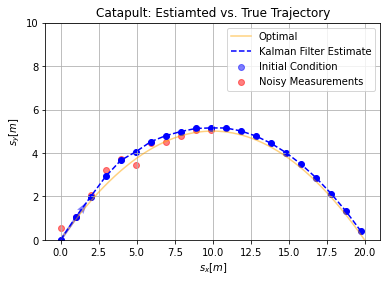

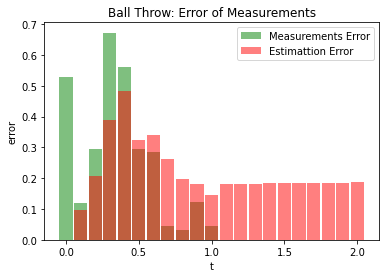

Mean Position Error of Estimation:  0.21263618447112387  [m]


In [3]:
# Initialize state
initial_state = np.concatenate((p0, v0)) # First state of our estimation. [position_x, position_y, velocity_x, velocity_y]^T
initial_covariance = np.eye(4) # First covariance of our estimation

# Initialise "sensor"
measurement_noise_R = np.diag([0.5, 0.5]) # Measurement noise should model the error of the observations
measurement_matrix_H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]]) 

# Initalise model
system_matrix_A = np.array([[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, 1, 0], [0, 0, 0, 1]])
input_matrix_B = np.diag([0, 0, 0, dt]) # Model systematic disturbance on the y velocity component
input_vector_u = np.array([[0], [0], [0], [-g]]) # Models gravity as a systematic disturbance 
error_influence_on_process = np.matrix([0.5 * np.power(dt, 2), 0.5 * np.power(dt, 2), dt, dt]) # How strong is the model error in each state variable
process_noise_Q = error_influence_on_process.T @ error_influence_on_process # Create Q based on the model error above. 

# Create buffers to store states
estimated_states = []
estimated_covariances = []
estimated_time = []
    
estimated_states.append(initial_state)
estimated_covariances.append(initial_covariance)
estimated_time.append(t0)

# Create running variavles for Kalman filter
time_t = t0
state_x = initial_state
covariance_P = initial_covariance

# Kalman filter loop
num_steps = len(t_observed)
for t in range(1,num_steps):
    # Prediction step
    predicted_state_x = system_matrix_A @ state_x + input_matrix_B @ input_vector_u
    predicted_covariance_P = system_matrix_A @ covariance_P @ system_matrix_A.T + process_noise_Q
    time_t = time_t + dt
    # Overwrite variables for prediction only
    state_x = predicted_state_x
    covariance_P = predicted_covariance_P
   
    # Update step
    kalman_gain = predicted_covariance_P @ measurement_matrix_H.T @ np.linalg.inv(measurement_matrix_H @ predicted_covariance_P @ measurement_matrix_H.T + measurement_noise_R)
    state_x = predicted_state_x + kalman_gain @ (s_observed[:,[t]] - measurement_matrix_H @ predicted_state_x)
    covariance_P = (np.eye(4) - kalman_gain @ measurement_matrix_H) @ predicted_covariance_P
    
    # Store variable in buffer
    estimated_states.append(state_x)
    estimated_covariances.append(covariance_P)
    estimated_time.append(time_t)

# Prediction capeability of model
for t in range(10):
    # Prediction step
    predicted_state_x = system_matrix_A @ predicted_state_x + input_matrix_B @ input_vector_u
    predicted_covariance_P = system_matrix_A @ predicted_covariance_P @ system_matrix_A.T + process_noise_Q
    time_t = time_t + dt
    
    # Store variable in buffer
    estimated_states.append(predicted_state_x)
    estimated_covariances.append(predicted_covariance_P)
    estimated_time.append(time_t)

# Copy buffer to numpy arrays
s_estimated = initial_state = np.concatenate((np.array([state[0] for state in estimated_states], dtype=object), np.array([state[1] for state in estimated_states], dtype=object)), 1).astype(float).T
t_estimated = np.array([time for time in estimated_time], dtype=object).astype(float)

# PLot estimation
ut.plot_estimation(p0, v0, s_true, s_observed, s_estimated);

# Computer and plot error in comparison to true trajectory
s_true_sampled_estimated = np.array([np.interp(t_estimated, t_true, s_true[0,:]), np.interp(t_estimated, t_true, s_true[1,:])])
s_error_estiamted = np.linalg.norm(s_estimated - s_true_sampled_estimated, 2, 0)
ut.plot_error_comparison(t_observed, s_error_observed, t_estimated, s_error_estiamted)

# Computer and print mean error
mean_error_estimated = np.mean(s_error_estiamted)
print('Mean Position Error of Estimation: ', mean_error_estimated, ' [m]')


<div style="padding: 20px; border: 5px solid;">
    <h2>Interactive Code Block 4: Evaluating Kalman Filter Performance</h2>
    <p>The saga of Charles the Little takes a riveting turn as we delve into the depths of velocity estimation. In the quest for a complete understanding of his thrown projectiles, Charles realizes that the Kalman Filter has more to offer than he initially thought.</p>
    <p>Your mission now is to evaluate the prowess of the Kalman Filter in estimating the velocity of the stone. It's fascinating to note that the Filter can even estimate velocity without ever directly measuring it!</p>
    <h3>Tasks:</h3>
    <ol>
        <li>Extract the estimated velocity components (x and y) from the estimated states.</li>
        <li>Prepare buffers to house the true velocity values (vx_true and vy_true) based on the provided equations.</li>
        <li>Calculate the error between the estimated velocity and the true velocity for both components.</li>
        <li>Use the provided utility function to craft a visual comparison of estimated velocity values against the true velocity values.</li>
        <li>Plot the error of the estimated velocity values compared to the true velocity values using plotted graphs.</li>
        <li>Compute and reveal the mean error of the estimated velocity values.</li>
    </ol> 
    <p>Feel free to add new code cells below to complete the tasks.</p>
</div>

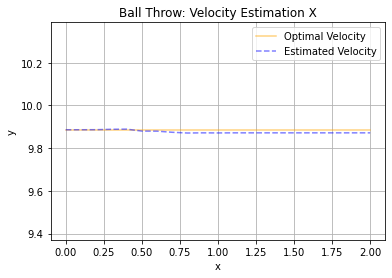

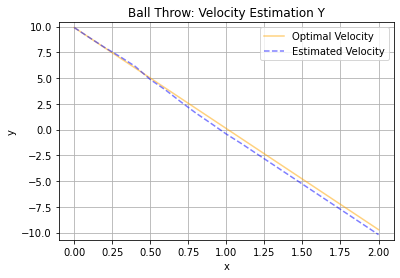

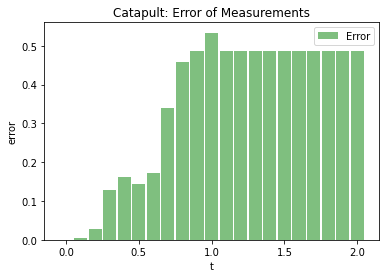

Mean Velocity Error of Estimation:  0.34894032722370455  [m/s] or  1.2561851780053364  [km/h]


In [4]:
vx_estimated = np.array([state[2] for state in estimated_states], dtype=object)
vy_estimated = np.array([state[3] for state in estimated_states], dtype=object)
v_estimated = initial_state = np.concatenate((vx_estimated, vy_estimated), 1).astype(float).T

v_true = np.array([
    np.tile(v0[0], (1, len(t_true)))[0],
    np.multiply(-g, t_true) + v0[1]
]) # Generate xy corrdinated of the true velocity


v_true_sampled_estimated = np.array([np.interp(t_estimated, t_true, v_true[0,:]), np.interp(t_estimated, t_true, v_true[1,:])])
v_error_estiamted = np.linalg.norm(v_estimated - v_true_sampled_estimated, 2, 0)

ut.plot_velocity_estimation(t_estimated, v_true_sampled_estimated[0, :], v_estimated[0, :], "X")
ut.plot_velocity_estimation(t_estimated, v_true_sampled_estimated[1, :], v_estimated[1, :], "Y")

ut.plot_error(t_estimated, v_error_estiamted)

mean_error_estimated = np.mean(v_error_estiamted)
print('Mean Velocity Error of Estimation: ', mean_error_estimated, ' [m/s] or ', mean_error_estimated*3.6, ' [km/h]')

<div style="padding: 20px; border: 5px solid;">
    <h2>Bonus Interactive Code Block: Partial Observations and Kalman Fill</h2>
    <p>As we embark on a thrilling new chapter of Charles the Little's saga, the battlefield setting poses a new challenge. Now, Charles finds himself facing a towering castle wall, obstructing his observations. Only the first half of his epic projectile journey is visible to his keen eyes.</p> 
    <p>In this bonus challenge, you'll embark on a quest to modify the Kalman Filter implementation. It must now rely on observations for only the initial 50% of the trajectory. However, Charles discovers the remarkable prediction power of the Kalman Filter, which aids in filling the trajectory gap.</p>   
    <h3>Tasks:</h3>
    <ol>
        <li>Alter the previous Kalman Filter implementation to utilize observations exclusively for the first 50% of the trajectory.</li>
        <li-Allow the Kalman Filter to harness its predictive prowess to complete the remaining trajectory.</li>
        <li>Engage in a discussion of the feasibility of this approach and the vital role played by the Kalman Filter's predictive capabilities in bridging the gap.</li>
        <li>Calculate and display the error between the estimated values and the true trajectory for the modified implementation.</li>
        <li>Compute and unveil the mean error of the estimated values using partial observations and Kalman fill.</li>
    </ol>
    <p>To tackle this challenge, you'll need to refine the existing Kalman Filter code. Don't hesitate to introduce new code cells below to accomplish the tasks.</p>
</div>